# 05 - Context and matchup
The match is at San Diego.

1. Home, away and last 6
2. Likely XI and shape
3. Substitutions
4. Build-up ball losses
5. Ball losses under pressure, by player
6. Runs in behind (SkillCorner)
7. Transitions
8. Left side: match by match

## Setup

In [1]:
import ast
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from mplsoccer import Pitch

pd.set_option("display.max_columns", 50)

In [2]:
PROCESSED_FOLDER = Path("../../data/processed")
FIGURES_FOLDER = Path("../../figures")

SD_COLOR = "#2a78d6"          # San Diego = blue
BACKGROUND = "#fcfcfb"
TEXT_COLOR = "#0b0b0b"
TEXT_MUTED = "#52514e"

In [3]:
events = pd.read_parquet(PROCESSED_FOLDER / "sb_events.parquet")
matches = pd.read_parquet(PROCESSED_FOLDER / "matches.parquet")
dynamic_events = pd.read_parquet(PROCESSED_FOLDER / "sc_dynamic.parquet")
physical = pd.read_parquet(PROCESSED_FOLDER / "physical.parquet")

sd_matches = matches[matches["focus_team"] == "San Diego"]
sd_matches = sd_matches.sort_values("match_date").reset_index(drop=True)

sd_events_all = events[events["focus_team"] == "San Diego"]
sd_own_events = sd_events_all[sd_events_all["team"] == "San Diego FC"]
opponent_events_vs_sd = sd_events_all[sd_events_all["team"] != "San Diego FC"]

nashville_events = events[events["focus_team"] == "Nashville"]
nashville_own_events = nashville_events[nashville_events["team"] == "Nashville SC"]

sd_matches[["match_date", "home_team", "away_team", "home_score", "away_score"]].tail(6)

,match_date,home_team,away_team,home_score,away_score
18,2025-06-26,Vancouver Whitecaps,San Diego FC,3.0,5.0
19,2025-06-29,FC Dallas,San Diego FC,2.0,3.0
20,2025-07-06,San Diego FC,Houston Dynamo,3.0,4.0
21,2025-07-13,Chicago Fire,San Diego FC,1.0,2.0
22,2025-07-17,San Diego FC,Toronto FC,0.0,1.0
23,2025-07-20,San Diego FC,Vancouver Whitecaps,1.0,1.0


In [4]:
def style_axis(ax):
    ax.set_facecolor(BACKGROUND)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.tick_params(colors=TEXT_MUTED)

## 1 - Home, away and last 6

In [5]:
sd_is_home = sd_matches["home_team"] == "San Diego FC"

all_ids = sd_matches["match_id"].tolist()
home_ids = sd_matches[sd_is_home]["match_id"].tolist()
away_ids = sd_matches[~sd_is_home]["match_id"].tolist()
last_6_ids = sd_matches["match_id"].iloc[-6:].tolist()     # matches are sorted by date

print("Home:", len(home_ids), "| Away:", len(away_ids))

Home: 13 | Away: 11


In [6]:
def non_penalty_shots(team_events):
    is_shot = team_events["type"] == "Shot"
    not_penalty = team_events["shot_type"] != "Penalty"
    return team_events[is_shot & not_penalty]


def split_profile(match_ids):
    sd_events = sd_own_events[sd_own_events["match_id"].isin(match_ids)]
    opponent_events = opponent_events_vs_sd[opponent_events_vs_sd["match_id"].isin(match_ids)]

    sd_shots = non_penalty_shots(sd_events)
    opponent_shots = non_penalty_shots(opponent_events)

    # set pieces = shots from corners and free kicks
    is_set_piece = sd_shots["play_pattern"].isin(["From Corner", "From Free Kick"])
    set_piece_xg = sd_shots[is_set_piece]["shot_statsbomb_xg"].sum()

    is_goal_kick = (sd_events["type"] == "Pass") & (sd_events["pass_type"] == "Goal Kick")
    goal_kicks = sd_events[is_goal_kick]

    return {
        "matches": len(match_ids),
        "xG against per game": opponent_shots["shot_statsbomb_xg"].sum() / len(match_ids),
        "% short goal kicks": (goal_kicks["end_x"] <= 40).mean() * 100,
        "% of their xG from set pieces": set_piece_xg / sd_shots["shot_statsbomb_xg"].sum() * 100,
    }

In [7]:
profiles = pd.DataFrame({
    "All matches": split_profile(all_ids),
    "Home": split_profile(home_ids),
    "Away": split_profile(away_ids),
    "Last 6": split_profile(last_6_ids),
})
profiles.round(1)

,All matches,Home,Away,Last 6
matches,24.0,13.0,11.0,6.0
xG against per game,1.1,0.7,1.7,1.4
% short goal kicks,77.9,87.3,69.9,86.1
% of their xG from set pieces,28.9,34.0,22.0,18.7


At home they concede 0.7 xG a game (1.7 away, 1.4 in the last 6). 87% of goal kicks are short at home. Set pieces are 34% of their xG at home.

## 2 - Likely XI and shape
From the Starting XI events, same as notebook 02.

In [8]:
starting_xi_rows = sd_own_events[sd_own_events["type"] == "Starting XI"]

lineup_rows = []
for index, row in starting_xi_rows.iterrows():
    tactics = ast.literal_eval(row["tactics"])
    for slot in tactics["lineup"]:
        lineup_rows.append({
            "match_id": row["match_id"],
            "formation": tactics["formation"],
            "player": slot["player"]["name"],
            "position": slot["position"]["name"],
        })

sd_lineups = pd.DataFrame(lineup_rows)

In [9]:
formations = sd_lineups.drop_duplicates("match_id")[["match_id", "formation"]]
formations = formations.merge(sd_matches[["match_id", "home_team"]], on="match_id")
formations["venue"] = np.where(formations["home_team"] == "San Diego FC", "Home", "Away")
formations.groupby(["venue", "formation"]).size()

venue  formation
Away   433          10
       41212         1
Home   433           9
       442           1
       41212         3
dtype: int64

Starters in the last 6 = most likely XI

In [10]:
last_6_starters = sd_lineups[sd_lineups["match_id"].isin(last_6_ids)]
starts_last_6 = last_6_starters["player"].value_counts()

# usual position = the position he played most in those games
position_counts = last_6_starters.groupby(["player", "position"]).size().reset_index(name="times")
position_counts = position_counts.sort_values("times", ascending=False)
usual_position = position_counts.drop_duplicates("player").set_index("player")["position"]

last_6_table = pd.DataFrame({"starts": starts_last_6, "usual position": usual_position})
last_6_table.sort_values("starts", ascending=False).head(14)

,starts,usual position
player,,
Jeppe Theis Tverskov,6,Center Defensive Midfield
Anders Laustrup Dreyer,6,Right Wing
Oscar Anthony Verhoeven,6,Right Back
Onni Johannes Simonpoika Valakari,6,Right Center Midfield
Christopher Donald McVey,5,Right Center Back
Luca Dylan Bombino,5,Left Back
Ian Pilcher,4,Left Center Back
Alexander Cole Mighten,4,Left Wing
Luca de la Torre,3,Left Center Midfield


## 3 - Substitutions
Game state = the score at the moment of each event (Leading, Level, Trailing).

In [11]:
def add_game_state(match_events, team_name):
    match_events = match_events.sort_values(["match_id", "index"]).copy()

    is_shot_goal = (match_events["type"] == "Shot") & (match_events["shot_outcome"] == "Goal")
    is_own_goal = match_events["type"] == "Own Goal For"
    is_goal = is_shot_goal | is_own_goal
    is_team = match_events["team"] == team_name

    # +1 for a goal for, -1 for a goal against
    match_events["goal_value"] = 0
    match_events.loc[is_goal & is_team, "goal_value"] = 1
    match_events.loc[is_goal & ~is_team, "goal_value"] = -1

    # goal difference before the event (the goal itself counts from the next event)
    running_total = match_events.groupby("match_id")["goal_value"].cumsum()
    goal_difference = running_total - match_events["goal_value"]

    match_events["game_state"] = "Level"
    match_events.loc[goal_difference > 0, "game_state"] = "Leading"
    match_events.loc[goal_difference < 0, "game_state"] = "Trailing"
    return match_events


sd_events_with_state = add_game_state(sd_events_all, "San Diego FC")
game_states = sd_events_with_state[["id", "game_state"]]

In [12]:
sd_subs = sd_own_events[sd_own_events["type"] == "Substitution"]
sd_subs = sd_subs.merge(game_states, on="id")

print("Substitutions per game:", round(len(sd_subs) / len(sd_matches), 1))
sd_subs.groupby("game_state").agg(changes=("minute", "size"), median_minute=("minute", "median"))

Substitutions per game: 4.2


,changes,median_minute
game_state,,
Leading,36,78.5
Level,28,70.5
Trailing,36,66.5


Position taken off vs position coming on

In [13]:
POSITION_GROUPS = {
    "Right Back": "Full-backs", "Left Back": "Full-backs",
    "Right Center Back": "Centre-backs", "Left Center Back": "Centre-backs",
    "Center Defensive Midfield": "Holding midfielder",
    "Right Center Midfield": "Central midfielders", "Left Center Midfield": "Central midfielders",
    "Right Defensive Midfield": "Central midfielders", "Left Defensive Midfield": "Central midfielders",
    "Center Attacking Midfield": "Central midfielders",
    "Right Wing": "Wingers", "Left Wing": "Wingers",
    "Center Forward": "Strikers", "Right Center Forward": "Strikers", "Left Center Forward": "Strikers",
}
sd_subs["position_group"] = sd_subs["position"].map(POSITION_GROUPS)

# position each replacement plays after coming on (his first event in that match)
events_with_position = sd_own_events.dropna(subset=["position"]).sort_values(["match_id", "index"])
first_position = events_with_position.drop_duplicates(["match_id", "player"])[["match_id", "player", "position"]]
first_position = first_position.rename(columns={"player": "substitution_replacement", "position": "replacement_position"})

sd_subs = sd_subs.merge(first_position, on=["match_id", "substitution_replacement"], how="left")
sd_subs["replacement_group"] = sd_subs["replacement_position"].map(POSITION_GROUPS)

like_for_like = sd_subs["position_group"] == sd_subs["replacement_group"]
print(f"Like-for-like changes: {like_for_like.mean():.0%} of {len(sd_subs)}")
pd.crosstab(sd_subs["position_group"], sd_subs["replacement_group"])      # rows = off, columns = on

Like-for-like changes: 79% of 100


replacement_group,Central midfielders,Centre-backs,Full-backs,Holding midfielder,Strikers,Wingers
position_group,,,,,,
Central midfielders,23,0,0,2,6,3
Centre-backs,0,4,0,0,0,0
Full-backs,0,1,28,0,0,0
Strikers,1,0,1,0,10,2
Wingers,0,0,0,0,5,14


In [14]:
# shape changes during games (Tactical Shift events), by game state
is_sd_shift = (sd_events_with_state["type"] == "Tactical Shift") & (sd_events_with_state["team"] == "San Diego FC")
sd_shifts = sd_events_with_state[is_sd_shift].copy()

new_formation = []
for tactics_text in sd_shifts["tactics"]:
    new_formation.append(ast.literal_eval(tactics_text)["formation"])
sd_shifts["new_formation"] = new_formation

pd.crosstab(sd_shifts["game_state"], sd_shifts["new_formation"])

new_formation,433,442,4231,41212
game_state,,,,
Leading,9,0,0,1
Level,3,0,2,0
Trailing,4,3,0,7


In [15]:
# goals scored by substitutes
replacements = sd_subs[["match_id", "substitution_replacement"]].rename(columns={"substitution_replacement": "player"})
is_sd_shot = (sd_own_events["type"] == "Shot") & (sd_own_events["shot_type"] != "Penalty")
substitute_shots = sd_own_events[is_sd_shot].merge(replacements, on=["match_id", "player"])
substitute_goals = substitute_shots[substitute_shots["shot_outcome"] == "Goal"]

print("Goals by substitutes:", len(substitute_goals))
print(substitute_goals["player"].value_counts())
print()
iloski_on = sd_subs[sd_subs["substitution_replacement"] == "Milan Iloski"]
print("Iloski off the bench:", len(iloski_on), "times, median minute", iloski_on["minute"].median())


Goals by substitutes: 11
player
Milan Iloski                         5
Tomas Ángel Gutiérrez                3
Onni Johannes Simonpoika Valakari    2
Hirving Rodrigo Lozano Bahena        1
Name: count, dtype: int64

Iloski off the bench: 11 times, median minute 71.0


79% of changes are like for like; most of the others put on an extra striker for a midfielder or winger. Changes come earlier when behind (median minute 66.5) than when leading (78.5). When behind they change shape: a diamond 7 times, a 4-4-2 3 times. Substitutes have scored 11 goals, Iloski 5 (off the bench 11 times, median minute 71).

## 4 - Build-up ball losses
Losses per 100 touches by zone, own and middle third.
Loss = dispossessed, miscontrol, incomplete or out-of-play pass, failed dribble.

In [16]:
TOUCH_TYPES = ["Pass", "Carry", "Ball Receipt*", "Shot", "Dribble", "Miscontrol"]


def get_touches(own_events):
    touches = own_events[own_events["type"].isin(TOUCH_TYPES)]
    return touches.dropna(subset=["x", "y"])


def get_ball_losses(own_events):
    is_dispossessed_or_miscontrol = own_events["type"].isin(["Dispossessed", "Miscontrol"])
    is_failed_pass = (own_events["type"] == "Pass") & own_events["pass_outcome"].isin(["Incomplete", "Out"])
    is_failed_dribble = (own_events["type"] == "Dribble") & (own_events["dribble_outcome"] == "Incomplete")
    losses = own_events[is_dispossessed_or_miscontrol | is_failed_pass | is_failed_dribble]
    return losses.dropna(subset=["x", "y"])


sd_touches = get_touches(sd_own_events)
sd_ball_losses = get_ball_losses(sd_own_events)
print("Ball losses per game:", round(len(sd_ball_losses) / len(sd_matches), 1))

Ball losses per game: 111.0


### Touches and losses in 9 zones
Thirds along x, lanes across y (y < 26.7 = San Diego's left).

In [17]:
pitch = Pitch(pitch_type="statsbomb", pitch_color="#3a7d44", line_color="white", line_zorder=2)

zone_edges = ([0, 40, 80, 120], [0, 80 / 3, 2 * 80 / 3, 80])     # (x edges, y edges)

touches_per_zone = pitch.bin_statistic(sd_touches["x"], sd_touches["y"], statistic="count", bins=zone_edges)
losses_per_zone = pitch.bin_statistic(sd_ball_losses["x"], sd_ball_losses["y"], statistic="count", bins=zone_edges)

loss_rate = losses_per_zone["statistic"] / touches_per_zone["statistic"] * 100
loss_rate.round(1)      # rows = lanes, columns = thirds

array([[ 5.9,  5.2, 12.5],
       [ 3.4,  3.7,  9.6],
       [ 6.2,  4.6, 10. ]])

In [18]:
# as a table
loss_rate_table = pd.DataFrame(loss_rate.round(1),
                               index=["Their left", "Centre", "Their right"],
                               columns=["Own third", "Middle third", "Final third"])
loss_rate_table

,Own third,Middle third,Final third
Their left,5.9,5.2,12.5
Centre,3.4,3.7,9.6
Their right,6.2,4.6,10.0


### Zone map
Build-up zones only. Light = secure, dark orange = most losses (one colour scale, readable for colour-blind viewers).

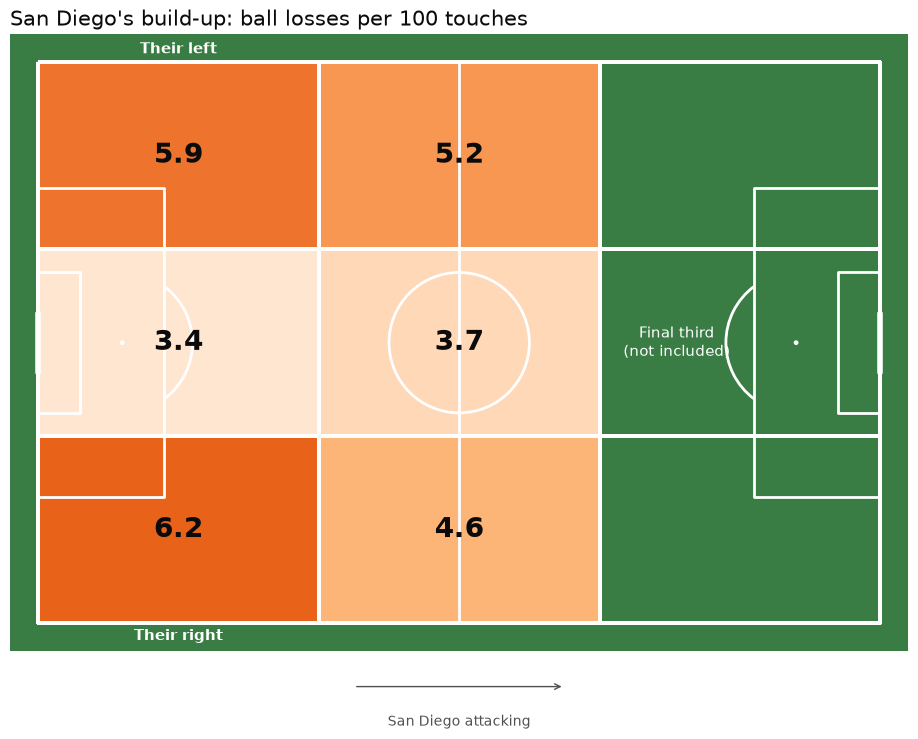

In [19]:
# no colour in the final third
build_up_rate = loss_rate.copy()
build_up_rate[:, 2] = np.nan

zone_map = losses_per_zone.copy()
zone_map["statistic"] = build_up_rate

LOSS_COLORS = LinearSegmentedColormap.from_list("loss_rate", ["#fff5eb", "#fdae6b", "#e6550d"])

fig, ax = pitch.draw(figsize=(11, 7.5))
fig.set_facecolor("white")
pitch.heatmap(zone_map, ax=ax, cmap=LOSS_COLORS, vmin=3, vmax=6.5, edgecolors="white", linewidth=1.5)

# print the rate in each coloured zone
for lane in range(3):
    for third in range(2):
        rate = build_up_rate[lane, third]
        ax.text(zone_map["cx"][lane, third], zone_map["cy"][lane, third], f"{rate:.1f}",
                ha="center", va="center", fontsize=20, color=TEXT_COLOR, fontweight="bold")

ax.text(91, 40, "Final third\n(not included)", ha="center", va="center", fontsize=11, color="white")
# lane labels in the green border around the pitch
ax.text(20, -1.8, "Their left", ha="center", va="center", fontsize=11, color="white", fontweight="bold")
ax.text(20, 81.8, "Their right", ha="center", va="center", fontsize=11, color="white", fontweight="bold")
ax.annotate("", xy=(75, 89), xytext=(45, 89), arrowprops=dict(arrowstyle="->", color=TEXT_MUTED), annotation_clip=False)
ax.text(60, 93, "San Diego attacking", ha="center", va="top", fontsize=10, color=TEXT_MUTED)
ax.set_title("San Diego's build-up: ball losses per 100 touches", fontsize=15, color=TEXT_COLOR, loc="left")

fig.savefig(FIGURES_FOLDER / "ex1_sd_ball_loss_rate_zones.png", dpi=200, bbox_inches="tight")
plt.show()

Own third: 3.4 losses per 100 touches in the centre, 5.9 and 6.2 on the flanks.

## 5 - Ball losses under pressure, by player
Own half only, same loss definition as section 4. Min. 100 touches under pressure.

In [20]:
in_own_half = sd_touches["x"] < 60
pressured_touches = sd_touches[in_own_half & (sd_touches["under_pressure"] == True)]

loss_in_own_half = sd_ball_losses["x"] < 60
pressured_losses = sd_ball_losses[loss_in_own_half & (sd_ball_losses["under_pressure"] == True)]

player_pressure = pd.DataFrame({
    "touches": pressured_touches.groupby("player").size(),
    "losses": pressured_losses.groupby("player").size(),
}).fillna(0)
player_pressure = player_pressure[player_pressure["touches"] >= 100]
player_pressure["losses per 100 touches"] = player_pressure["losses"] / player_pressure["touches"] * 100
player_pressure.sort_values("losses per 100 touches", ascending=False).round(1)

,touches,losses,losses per 100 touches
player,,,
Luca Dylan Bombino,191,31,16.2
Oscar Anthony Verhoeven,135,21,15.6
Anders Laustrup Dreyer,205,23,11.2
Hirving Rodrigo Lozano Bahena,127,14,11.0
Luca de la Torre,229,24,10.5
Patrick James Coleman McNair,258,25,9.7
Ian Pilcher,102,9,8.8
Onni Johannes Simonpoika Valakari,265,23,8.7
Christopher Donald McVey,353,26,7.4


Full-backs Bombino and Verhoeven lose the ball most under pressure in their own half (16.2 and 15.6 per 100 touches), more than double Tverskov (6.7) and McVey (7.4).

Nashville as a baseline: is this normal for the position?

In [21]:
def role_group(position):
    if "Center Back" in position:
        return "Centre-backs"
    if "Back" in position:
        return "Full-backs"
    if "Defensive Midfield" in position:
        return "Holding midfielders"
    return "Other"


def pressured_loss_rate_by_role(own_events):
    touches = get_touches(own_events)
    losses = get_ball_losses(own_events)

    # own half, under pressure
    touches = touches[(touches["x"] < 60) & (touches["under_pressure"] == True)].copy()
    losses = losses[(losses["x"] < 60) & (losses["under_pressure"] == True)].copy()

    touches["role"] = touches["position"].fillna("").apply(role_group)
    losses["role"] = losses["position"].fillna("").apply(role_group)

    touches_per_role = touches.groupby("role").size()
    losses_per_role = losses.groupby("role").size()
    return losses_per_role / touches_per_role * 100

In [22]:
role_table = pd.DataFrame({
    "San Diego": pressured_loss_rate_by_role(sd_own_events),
    "Nashville": pressured_loss_rate_by_role(nashville_own_events),
})
role_table.round(1)      # losses per 100 touches under pressure, own half

,San Diego,Nashville
role,,
Centre-backs,8.2,9.2
Full-backs,14.9,13.9
Holding midfielders,6.2,9.6
Other,9.3,14.8


Full-backs lose the ball about as often for both teams (14.9 vs 13.9), so Bombino and Verhoeven are normal for their position. Tverskov (6.7) is far more secure than Nashville's holding midfielders (9.6). So the press should go wide, not through the middle.

## 6 - Runs in behind (SkillCorner)
- Physical: top speed, sprints per 60 minutes in play. Only rows that pass SkillCorner's quality check.
- Dynamic events: runs behind the defensive line.

In [23]:
sd_sc_match_ids = sd_matches["sc_match_id"]
in_sd_match = physical["match_id"].isin(sd_sc_match_ids)
is_sd_player = physical["team_name"] == "San Diego FC"      # the physical file uses the full name
sd_physical = physical[in_sd_match & is_sd_player]

print("San Diego player-match rows:", len(sd_physical))
print("Passing the quality check:", sd_physical["physical_check_passed"].sum())

San Diego player-match rows: 341
Passing the quality check: 339


In [24]:
# minutes from all rows
minutes_per_player = sd_physical.groupby("player_short_name")["minutes_full_all"].sum()

# speed and sprints: quality-checked rows only
checked = sd_physical[sd_physical["physical_check_passed"] == True]
top_speed = checked.groupby("player_short_name")["psv99"].max()
sprints_per_60 = checked.groupby("player_short_name")["sprint_count_full_bip_p60bip"].mean()

In [25]:
is_sd_run = (dynamic_events["match_id"].isin(sd_sc_match_ids)
             & (dynamic_events["event_type"] == "off_ball_run")
             & (dynamic_events["team_shortname"] == "San Diego"))
sd_runs = dynamic_events[is_sd_run]

runs_behind = sd_runs[sd_runs["event_subtype"] == "behind"]
runs_behind_per_player = runs_behind.groupby("player_name").size()

Same short names in both files ("A. Dreyer"). Runs per 90.

In [26]:
pace_and_runs = pd.DataFrame({
    "minutes": minutes_per_player,
    "top_speed_kmh": top_speed,
    "sprints_per_60": sprints_per_60,
    "runs_behind": runs_behind_per_player,
})
pace_and_runs["runs_behind"] = pace_and_runs["runs_behind"].fillna(0)
pace_and_runs["runs_behind_per_90"] = pace_and_runs["runs_behind"] / pace_and_runs["minutes"] * 90

regular_players = pace_and_runs[pace_and_runs["minutes"] >= 450]
regular_players = regular_players.sort_values("runs_behind_per_90", ascending=False)
regular_players.head(8).round(1)

,minutes,top_speed_kmh,sprints_per_60,runs_behind,runs_behind_per_90
M. Iloski,581.5,33.6,16.6,56.0,8.7
T. Ángel,716.6,31.3,13.7,68.0,8.5
H. Lozano,1368.8,32.7,15.6,118.0,7.8
A. Dreyer,2377.0,32.0,11.8,188.0,7.1
A. Mighten,1035.1,32.6,11.8,65.0,5.7
L. de la Torre,1720.1,29.6,8.7,55.0,2.9
O. Valakari,1788.1,29.1,8.0,46.0,2.3
O. Verhoeven,1028.5,32.1,14.5,21.0,1.8


Iloski makes the most runs in behind per 90 (8.7), with the highest top speed (33.6 km/h) and the most sprints. Dreyer makes the most in total (188).

## 7 - Transitions
Fast attack = open-play possession with a shot within 15 seconds of the possession starting.

In [27]:
events["seconds"] = events["minute"] * 60 + events["second"]

# when each possession starts
possession_start = events.groupby(["match_id", "possession"])["seconds"].min()
possession_start = possession_start.reset_index(name="possession_start")

In [28]:
is_shot = (events["type"] == "Shot") & (events["shot_type"] != "Penalty")
all_shots = events[is_shot].merge(possession_start, on=["match_id", "possession"])

all_shots["seconds_into_possession"] = all_shots["seconds"] - all_shots["possession_start"]
is_open_play = all_shots["play_pattern"] == "Regular Play"
is_quick = all_shots["seconds_into_possession"] <= 15
all_shots["fast_attack"] = is_open_play & is_quick

In [29]:
for focus_team, team_name in [("San Diego", "San Diego FC"), ("Nashville", "Nashville SC")]:
    team_shots = all_shots[(all_shots["focus_team"] == focus_team) & (all_shots["team"] == team_name)]
    fast_shots = team_shots[team_shots["fast_attack"]]

    goals = (team_shots["shot_outcome"] == "Goal").sum()
    fast_goals = (fast_shots["shot_outcome"] == "Goal").sum()
    print(f"{team_name}: {fast_goals} of {goals} non-penalty goals from fast attacks")

San Diego FC: 15 of 43 non-penalty goals from fast attacks
Nashville SC: 5 of 34 non-penalty goals from fast attacks


### Where the fast attacks start
Where San Diego won the ball (first own event of the possession), for possessions with a fast-attack shot.

In [30]:
is_sd_fast_shot = (all_shots["focus_team"] == "San Diego") & (all_shots["team"] == "San Diego FC") & all_shots["fast_attack"]
sd_fast_shots = all_shots[is_sd_fast_shot]

first_own_event = sd_own_events.dropna(subset=["x"]).sort_values(["match_id", "index"]).drop_duplicates(["match_id", "possession"])
first_own_event = first_own_event[["match_id", "possession", "x"]]

fast_possessions = sd_fast_shots[["match_id", "possession"]].drop_duplicates()
fast_possessions = fast_possessions.merge(first_own_event, on=["match_id", "possession"], how="left")
fast_possessions["won the ball in"] = pd.cut(fast_possessions["x"], bins=[0, 40, 80, 120],
                                             labels=["Own third", "Middle third", "Final third"], include_lowest=True)

fast_goal_possessions = sd_fast_shots[sd_fast_shots["shot_outcome"] == "Goal"][["match_id", "possession"]]
fast_goal_possessions = fast_goal_possessions.merge(fast_possessions, on=["match_id", "possession"])

fast_starts = pd.DataFrame({
    "fast attacks": fast_possessions["won the ball in"].value_counts(),
    "goals": fast_goal_possessions["won the ball in"].value_counts(),
}).loc[["Own third", "Middle third", "Final third"]]
fast_starts


,fast attacks,goals
won the ball in,,
Own third,14,5
Middle third,34,7
Final third,21,3


In [31]:
print("Fast-attack goals by player:")
print(sd_fast_shots[sd_fast_shots["shot_outcome"] == "Goal"]["player"].value_counts().head(4))


Fast-attack goals by player:
player
Anders Laustrup Dreyer           4
Milan Iloski                     4
Hirving Rodrigo Lozano Bahena    3
Marcus Højriis Ingvartsen        1
Name: count, dtype: int64


In [32]:
# share of San Diego's shots that come from fast attacks, by game state
is_sd_shot = (all_shots["focus_team"] == "San Diego") & (all_shots["team"] == "San Diego FC")
sd_all_shots = all_shots[is_sd_shot].merge(game_states, on="id")

fast_share_by_state = sd_all_shots.groupby("game_state")["fast_attack"].mean() * 100
fast_share_by_state.round(0)

game_state
Leading     34.0
Level       23.0
Trailing    13.0
Name: fast_attack, dtype: float64

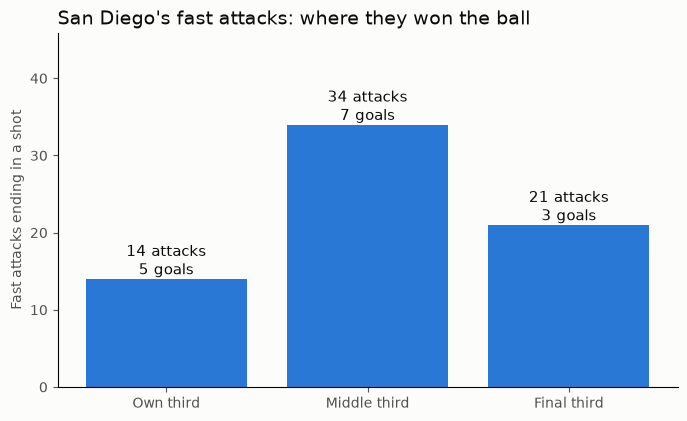

In [33]:
fig, ax = plt.subplots(figsize=(8, 4.6))
fig.set_facecolor(BACKGROUND)
style_axis(ax)

ax.bar(fast_starts.index, fast_starts["fast attacks"], color=SD_COLOR)
for position, (zone, row) in enumerate(fast_starts.iterrows()):
    label = f"{row['fast attacks']:.0f} attacks\n{row['goals']:.0f} goals"
    ax.text(position, row["fast attacks"] + 0.6, label, ha="center", fontsize=11, color=TEXT_COLOR)

ax.set_ylim(0, fast_starts["fast attacks"].max() * 1.35)
ax.set_ylabel("Fast attacks ending in a shot", color=TEXT_MUTED)
ax.set_title("San Diego's fast attacks: where they won the ball", fontsize=14, color=TEXT_COLOR, loc="left")

fig.savefig(FIGURES_FOLDER / "ex1_fast_attack_starts.png", dpi=200, bbox_inches="tight")
plt.show()


Half of their fast attacks start from winning the ball in midfield, and 7 of the 15 goals. A third of their shots when leading come from fast attacks, so going behind gives them more space to counter.

## 8 - Left side: match by match
How many of the 24 games had more opponent entries down San Diego's left than its right? Same entry definition as notebook 03.

In [34]:
def final_third_entries(team_events):
    # completed passes and carries crossing x = 80
    is_pass_or_carry = team_events["type"].isin(["Pass", "Carry"])
    crosses_line = (team_events["x"] < 80) & (team_events["end_x"] >= 80)
    entries = team_events[is_pass_or_carry & crosses_line]

    is_carry = entries["type"] == "Carry"
    is_completed_pass = entries["pass_outcome"].isna()
    return entries[is_carry | is_completed_pass]


entries_vs_sd = final_third_entries(opponent_events_vs_sd).copy()

# opponent's right (end_y > 53.3) = San Diego's left
entries_vs_sd["sd_left"] = entries_vs_sd["end_y"] > 2 * 80 / 3
entries_vs_sd["sd_right"] = entries_vs_sd["end_y"] < 80 / 3
entries_per_match = entries_vs_sd.groupby("match_id")[["sd_left", "sd_right"]].sum()

more_down_left = (entries_per_match["sd_left"] > entries_per_match["sd_right"]).sum()
print("Games with more entries down San Diego's left:", more_down_left, "of", len(entries_per_match))

Games with more entries down San Diego's left: 15 of 24


A tendency, not a rule: more down the left in 15 of 24 games.